# DDIM-LI Manuscript Figures — v2 (regenerated data, 10-month test)

Parallel to `generate_figures.ipynb` (left untouched). Same journal style block and
Figure 1 map cell, copied verbatim from it. All numbers come from the v2 test runs in
`outputs/v2/test_all/` (1 Nov 2025 – 28 Aug 2026, 3,672 sequences); see the project
results document for the values each figure should reproduce.

Figure plan: 1 study regions (your map) · 2 headline AP with 95% CIs · 3 example case
(diffusion ensemble) · 4 initiation vs continuation · 5 attribution (CNN ablation, IR-only
CNN, LightGBM permutation importance) · 6 calibration and area probabilities ·
S1 region × month AP. Saved-figure rules applied: reliability bins with < 100 samples are
omitted; region × month cells with too few lightning events are greyed out.

Run from the `manuscript/` directory. `savefig` lines are commented out, as in v1.

In [ ]:
import os, sys, csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
from scipy.ndimage import maximum_filter
import cartopy.crs as ccrs

REPO_ROOT = os.path.abspath("..")
sys.path.insert(0, REPO_ROOT)
sys.path.insert(0, os.path.join(REPO_ROOT, "baseline_cnn"))

# ---- Journal-style white theme, matching baseline_cnn/evaluate_cnn.py's _make_plots ----
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "black", "axes.labelcolor": "black",
    "xtick.color": "black", "ytick.color": "black", "text.color": "black",
    "grid.color": "#cccccc", "grid.linestyle": "--", "grid.linewidth": 0.5,
    "legend.framealpha": 0.9, "legend.edgecolor": "#cccccc", "font.size": 10,
    
    'axes.titlesize': 18,     # Font size of the plot title
    'axes.labelsize': 14,     # Font size of the x and y labels
    'font.weight': 'bold',    # Makes all text elements bold by default
    'axes.labelweight': 'bold', # Ensures axis labels explicitly inherit bold weight
    'axes.titleweight': 'bold'
})

def styled_ax(ax):
    ax.set_facecolor("white")
    ax.tick_params(colors="black")
    for s in ax.spines.values():
        s.set_edgecolor("black"); s.set_linewidth(0.8)
    ax.grid(True, color="#cccccc", linestyle="--", linewidth=0.5, zorder=0)


FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)

T = "../outputs/v2/test_all"
A = f"{T}/analysis"
import glob
def _pr(d):  # the run's PR-sample file, whatever its prefix
    g = sorted(glob.glob(f"{T}/{d}/*pr_curves.npz")) + sorted(glob.glob(f"{T}/{d}/plot_data.npz"))
    return g[0] if g else f"{T}/{d}/<missing>"

# ==== v2 output paths (edit if your folders differ) ====
PATHS = {
    "diffusion_npz":     f"{T}/diffusion/plot_data.npz",
    "cnn_npz":           _pr("cnn"),
    "cnn_ir_only_npz":   _pr("cnn_ir_only"),
    "lightgbm_npz":      _pr("lightgbm"),
    "pysteps_li_npz":    _pr("pysteps_li"),
    "pysteps_ir_npz":    _pr("pysteps_ir"),
    "persistence_npz":   _pr("persistence"),
    "regime_csv":        f"{A}/regime_initiation_continuation.csv",
    "brier_csv":         f"{A}/calibration_brier.csv",
    "region_month_csv":  f"{A}/region_month_skill.csv",
    "cnn_ablation_csv":  f"{A}/cnn_ablation.csv",
    "permutation_csv":   f"{A}/permutation_importance.csv",
    "area_recal_csv":    f"{T}/area_recal/area_recal_comparison.csv",
    "example_cases_npz": "./example_cases.npz",
}
FIGSIZE = (9,9)
DT_MIN, T_OUT = 10, 6
LEAD_TIMES = [(t + 1) * DT_MIN for t in range(T_OUT)]
PIXEL_SIZE_KM = 3.14            # v2 grid (was 4.0 in v1)
N_BOOT_FIG = 1000               # CIs for Figure 2 (cached after the first run)
MIN_BIN_COUNT = 100             # reliability: omit sparser bins (saved figure rule)
MIN_EVENTS_CELL = 1000          # region x month: grey out cells with fewer lightning pixels

# One colour / line style per model, used by every figure (matches analysis_regimes.py)
MODELS = {   # key: (label, colour, linestyle)
    "diffusion":   ("Diffusion (CNN-conditioned)", "#1f77b4", "-"),
    "cnn":         ("CNN",                         "#ff7f0e", "-"),
    "cnn_ir_only": ("CNN, IR only",                "#ff7f0e", "--"),
    "lightgbm":    ("LightGBM",                    "#2ca02c", "-"),
    "pysteps_li":  ("Optical flow (LI)",           "#9467bd", "-"),
    "pysteps_ir":  ("Optical flow (IR)",           "#8c564b", "-"),
    "persistence": ("Persistence",                 "#d62728", "-"),
}

def have(key):
    p = PATHS[key]
    ok = os.path.isfile(p)
    if not ok:
        print(f"[missing] {key} -> {p}  (edit PATHS or generate this file first)")
    return ok

def read_csv(key):
    with open(PATHS[key]) as f:
        return list(csv.DictReader(f))

## Figure 1 — Study regions

Your map cell from `generate_figures.ipynb`, copied unchanged.

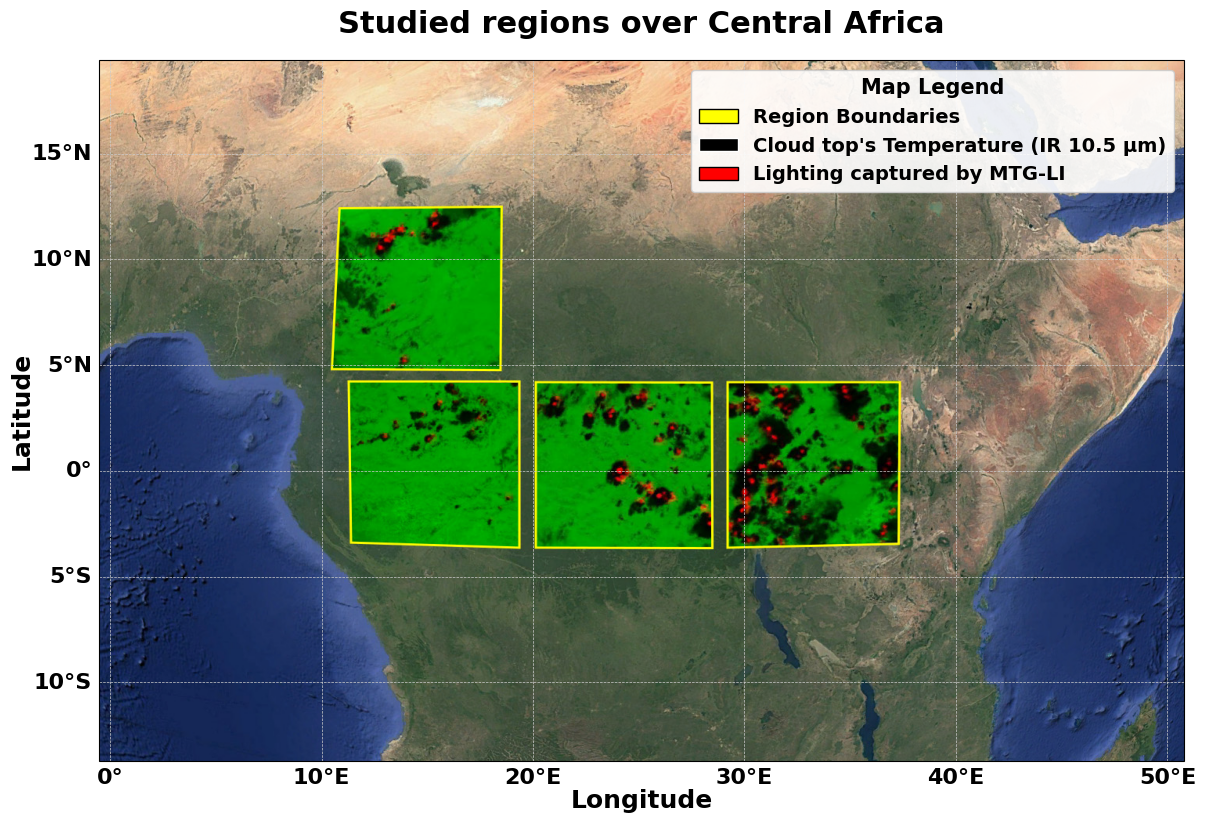

In [3]:
import os
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Patch

# 1. Load your Google Earth screenshot
# Replace with your actual directory path and filename
# IMAGE_PATH = "path/to/your/google_earth_screenshot.jpg" 
image_data = plt.imread(os.path.join(FIGDIR,'regions_map.jpg'))

# 2. Define the exact spatial footprint of your screenshot
# Format: [Left_Lon, Right_Lon, Bottom_Lat, Top_Lat]
# Example coordinates (replace these with your exact Google Earth edge values)
img_extent = [-0.5174, 50.7887, -13.7152, 19.4096] 

# 3. Use PlateCarree projection (standard Lat/Lon mapping)
map_projection = ccrs.PlateCarree()

# 4. Build the plot structure
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(1, 1, 1, projection=map_projection)

# Set the map frame to perfectly match your screenshot boundaries
ax.set_extent(img_extent, crs=map_projection)

# 5. Add gridlines and lat/lon coordinate numbers
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False   # Clean up layout by hiding top labels
gl.right_labels = False # Clean up layout by hiding right labels
gl.xlabel_style = {'size': 16, 'weight': 'bold'}
gl.ylabel_style = {'size': 16, 'weight': 'bold'}

# 6. Add "Longitude" and "Latitude" axis titles outside the box
ax.text(0.5, -0.04, 'Longitude', transform=ax.transAxes, 
        ha='center', va='top', fontsize=18, fontweight='bold')
ax.text(-0.06, 0.5, 'Latitude', transform=ax.transAxes, 
        ha='right', va='center', rotation='vertical', fontsize=18, fontweight='bold')

# 7. Overlap the screenshot image onto the map
# origin='upper' is mandatory for standard JPG/PNG images
ax.imshow(image_data, 
          extent=img_extent, 
          transform=map_projection, 
          origin='upper')

plt.title('Studied regions over Central Africa', fontsize=22, pad=20)
# -------------------------------------------------------------
# 8. Define Custom Legend Elements
# -------------------------------------------------------------
# Use Patch for filled boxes (e.g., regions, surface types)
# Use Line2D for lines (e.g., rivers, tracks, boundaries)
legend_elements = [
    Patch(facecolor='yellow', edgecolor='black', label='Region Boundaries'),
    Patch(facecolor='black', edgecolor='white', alpha=1, label='Cloud top\'s Temperature (IR 10.5 μm)'),
    Patch(facecolor='red', edgecolor='black', alpha=1, label='Lighting captured by MTG-LI'),
]

# -------------------------------------------------------------
# 9. Add the Legend to your Axis
# -------------------------------------------------------------
ax.legend(
    handles=legend_elements, 
    loc='upper right',        # Positions the legend inside the map
    frameon=True,            # Draws a background box for readability over imagery
    facecolor='white',       # Legend background color
    framealpha=0.9,          # Opacity of the background box (0 = see through, 1 = solid)
    fontsize=14, 
    title='Map Legend',      # Optional title for the legend box
    title_fontsize=15
)
# fig.savefig(os.path.join(FIGDIR, "fig1_regions_plot.jpg"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


## Figure 2 — Headline skill: AP vs lead time, 95% sequence-bootstrap CIs

Average precision (AP) for every model. CIs use `bootstrap_pr_auc_ci.bootstrap_ci` (same
sequence-level resampling as the reported tables, fast exact path). The first run caches
the numbers in `figures/fig2_ap_ci_cache.csv`; delete that file to recompute.

In [ ]:
from bootstrap_pr_auc_ci import load_run, bootstrap_ci, average_precision

CACHE = os.path.join(FIGDIR, "fig2_ap_ci_cache.csv")
order = ["cnn", "diffusion", "cnn_ir_only", "lightgbm", "pysteps_ir", "pysteps_li", "persistence"]
if os.path.isfile(CACHE):
    ap = {}
    for r in csv.DictReader(open(CACHE)):
        ap.setdefault(r["model"], []).append((float(r["ap"]), float(r["lo"]), float(r["hi"])))
else:
    ap, rows = {}, []
    for m in order:
        if not have(f"{m}_npz"):
            continue
        run, rng = load_run(PATHS[f"{m}_npz"]), np.random.default_rng(0)
        for t in sorted(run):
            r = bootstrap_ci(*run[t], N_BOOT_FIG, rng, metric=average_precision)
            ap.setdefault(m, []).append((r["point"], r["ci_lo"], r["ci_hi"]))
            rows.append(dict(model=m, lead_min=LEAD_TIMES[t], ap=r["point"], lo=r["ci_lo"], hi=r["ci_hi"]))
        print(f"{m}: done")
    with open(CACHE, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)

fig, ax = plt.subplots(figsize=(8, 6))
for m in order:
    if m not in ap:
        continue
    lab, col, ls = MODELS[m]
    v = np.array(ap[m])
    ax.plot(LEAD_TIMES, v[:, 0], color=col, linestyle=ls, linewidth=2, marker="o", markersize=5, label=lab)
    ax.fill_between(LEAD_TIMES, v[:, 1], v[:, 2], color=col, alpha=0.18)
ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Average precision")
ax.set_ylim(0, 1); ax.set_xticks(LEAD_TIMES)
ax.set_title("Lightning nowcast skill (test, Nov 2025 – Aug 2026)", pad=20)
styled_ax(ax)
ax.legend(fontsize=10)
fig.tight_layout()
# fig.savefig(os.path.join(FIGDIR, "fig2_headline_ap.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Figure 3 — Example case

Same rendering as your v1 cell (context IR, ground truth, ensemble members, with colour
bars). Regenerate `example_cases.npz` with the **CNN-conditioned** model first:

```bash
python select_example_cases.py --config configs/evaluate.yaml     --checkpoint outputs/v2/ir_li_cnncond/best.pt --output_dir manuscript --n_scan 60 --n_members 50
```

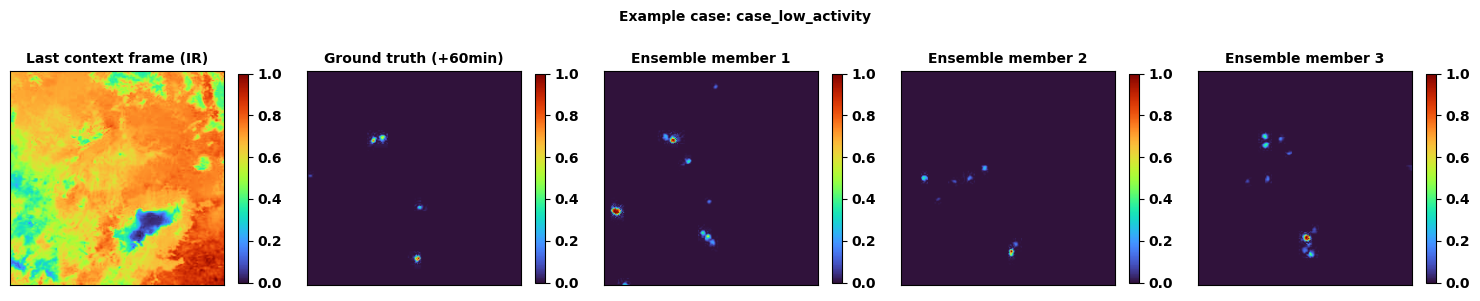

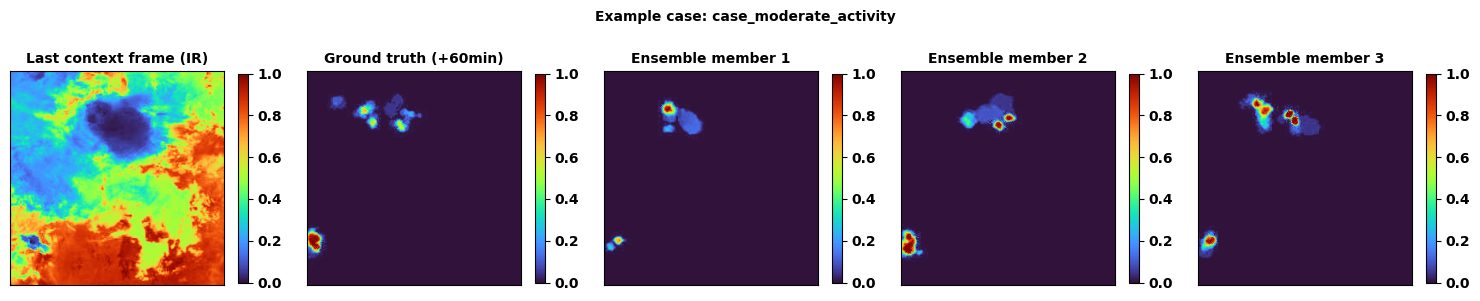

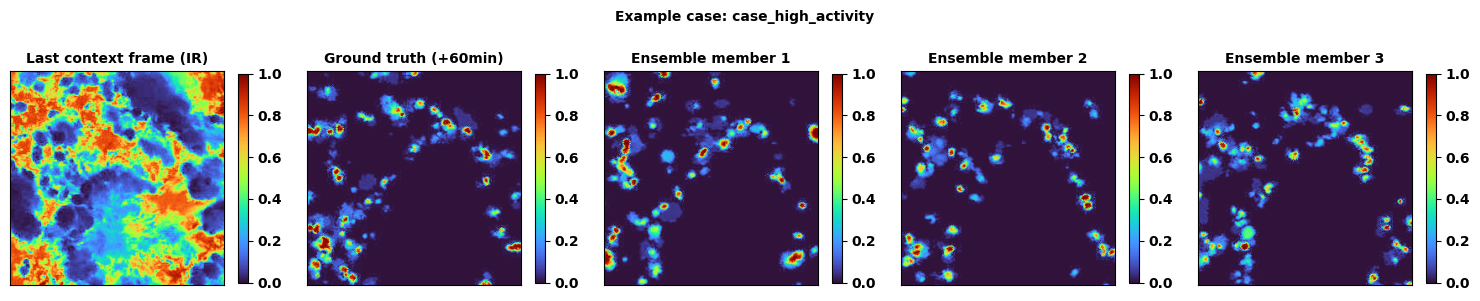

In [7]:
if have("example_cases_npz"):
    data = np.load(PATHS["example_cases_npz"], allow_pickle=True)
    case_names = [k.split("_context_ir")[0] for k in data.files if k.endswith("_context_ir")]

    for case in case_names:
        ctx_ir = data[f"{case}_context_ir"]        # (T_in, H, W)
        tgt_li = data[f"{case}_target_li"]          # (T_out, H, W)
        ens_li = data[f"{case}_ensemble_li"]        # (n_members, T_out, H, W)
        n_show_members = min(3, ens_li.shape[0])

        n_cols = 2 + n_show_members
        fig, axes = plt.subplots(1, n_cols, figsize=(3 * n_cols, 3.2))
        
        # Plot context frame with colorbar
        im0 = axes[0].imshow(ctx_ir[-1], cmap="turbo")
        axes[0].set_title("Last context frame (IR)", fontsize=10)
        plt.colorbar(im0, ax=axes[0], shrink=0.8)
        
        # Plot ground truth with colorbar
        im1 = axes[1].imshow(tgt_li[-1], cmap="turbo", vmin=0, vmax=1)
        axes[1].set_title("Ground truth (+60min)", fontsize=10)
        plt.colorbar(im1, ax=axes[1], shrink=0.8)
        
        # Plot ensemble members with colorbars
        for m in range(n_show_members):
            im = axes[2 + m].imshow(ens_li[m, -1], cmap="turbo", vmin=0, vmax=1)
            axes[2 + m].set_title(f"Ensemble member {m+1}", fontsize=10)
            plt.colorbar(im, ax=axes[2 + m], shrink=0.8)
            
        for ax in axes:
            ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(f"Example case: {case}", fontweight="bold", fontsize=10)
        fig.tight_layout()
        #fig.savefig(os.path.join(FIGDIR, f"fig4_example_{case}.png"), dpi=300, bbox_inches="tight", facecolor="white")
        plt.show()

## Figure 4 — Storm initiation vs continuation

Initiation = no lightning within 20 km in the last 30 min of context. Shaded band = 95%
CI of the diffusion model (the reference run of `analysis_regimes.py`); dotted = base rate.

In [ ]:
if have("regime_csv"):
    rows = read_csv("regime_csv")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for ax, regime, title in zip(axes, ["initiation", "continuation"],
                                 ["(a) Initiation: new lightning", "(b) Continuation: ongoing lightning"]):
        rr = [r for r in rows if r["regime"] == regime]
        for m in ["cnn", "diffusion", "cnn_ir_only", "lightgbm", "pysteps_ir", "pysteps_li", "persistence"]:
            s = sorted((float(r["lead_min"]), r) for r in rr if r["model"] == m)
            if not s:
                continue
            lab, col, ls = MODELS[m]
            x = [a for a, _ in s]; y = [float(r["pr_auc"]) for _, r in s]
            ax.plot(x, y, color=col, linestyle=ls, linewidth=2, marker="o", markersize=5, label=lab)
            if s[0][1]["ci_lo"] not in ("", "nan"):
                ax.fill_between(x, [float(r["ci_lo"]) for _, r in s], [float(r["ci_hi"]) for _, r in s],
                                color=col, alpha=0.18)
        base = sorted((float(r["lead_min"]), float(r["base_rate"])) for r in rr if r["model"] == "diffusion")
        ax.plot([a for a, _ in base], [b for _, b in base], color="black", linestyle=":", linewidth=1.5,
                label="Base rate (no skill)")
        ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Average precision"); ax.set_xticks(LEAD_TIMES)
        ax.set_title(title, pad=15)
        styled_ax(ax)
    axes[1].set_ylim(0, 1)
    axes[0].legend(fontsize=9)
    fig.tight_layout()
    # fig.savefig(os.path.join(FIGDIR, "fig4_initiation_continuation.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

## Figure 5 — Where the skill comes from

(a) Initiation AP of the CNN with parts of its 6 h context altered, and of the CNN trained
on IR only. (b) The same for all pixels. (c) LightGBM permutation importance (AP drop when a
predictor is shuffled), all pixels. Neighbourhood-lightning predictors are zero by definition
at initiation pixels, so initiation importance is not plotted for them (see results notes).

In [ ]:
VARIANTS = {   # cnn_ablation.csv variant: (label, colour, linestyle)
    "none":      ("CNN (full context)",                  "#ff7f0e", "-"),
    "ir_frozen": ("IR frozen at current frame",          "#1f77b4", "-"),
    "ir_swap":   ("IR from another scene",               "#1f77b4", ":"),
    "li_frozen": ("Lightning frozen at current frame",   "#2ca02c", "-"),
    "li_swap":   ("Lightning from another scene",        "#2ca02c", ":"),
}
PRETTY = {
    "li_local_max_9": "Lightning intensity nearby (now)", "li_local_max_recent_9": "Lightning nearby (last 30 min)",
    "li_local_count_9": "Lightning extent nearby (now)", "li_now_phys": "Lightning at pixel (now)",
    "ir_local_min_9": "Coldest cloud top nearby", "ir_min_ctx": "Coldest cloud top at pixel (6 h)",
    "ir_mean_ctx": "Mean cloud top at pixel (6 h)", "ir_local_mean_9": "Mean cloud top nearby",
    "ir_now": "Cloud top at pixel (now)", "ir_trend_30min": "Cloud-top cooling (30 min)",
    "ir_trend_2h": "Cloud-top cooling (2 h)", "ir_max_ctx": "Warmest cloud top at pixel (6 h)",
    "ir_std_ctx": "Cloud-top variability (6 h)", "li_time_since_last_active": "Time since lightning at pixel",
    "li_count_active_ctx": "Lightning frames at pixel (6 h)", "li_frac_active_ctx": "Lightning fraction at pixel (6 h)",
    "li_active_now": "Lightning at pixel (now, binary)", "li_recent_active_30min": "Lightning at pixel (30 min, binary)",
    "GROUP: all LI (lightning history) features": "ALL lightning predictors",
    "GROUP: all IR (cloud-top) features": "ALL cloud-top (IR) predictors",
    "GROUP: IR cooling trends (30 min, 2 h)": "Cloud-top cooling trends (group)",
    "GROUP: IR current state (now, local mean/min)": "Current cloud-top state (group)",
}
if have("cnn_ablation_csv"):
    ab = read_csv("cnn_ablation_csv")
    reg = read_csv("regime_csv") if have("regime_csv") else []
    pi = read_csv("permutation_csv") if have("permutation_csv") else []
    fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={"width_ratios": [1, 1, 1.25]})
    for ax, key, title, regime in [(axes[0], "ap_initiation", "(a) Initiation", "initiation"),
                                   (axes[1], "ap_all", "(b) All pixels", None)]:
        for v, (lab, col, ls) in VARIANTS.items():
            s = sorted((float(r["lead_min"]), float(r[key])) for r in ab if r["variant"] == v)
            if s:
                ax.plot([a for a, _ in s], [b for _, b in s], color=col, linestyle=ls, linewidth=2,
                        marker="o", markersize=4, label=lab)
        s = sorted((float(r["lead_min"]), float(r["pr_auc"])) for r in reg
                   if r["model"] == "cnn_ir_only" and (regime is None or r["regime"] == regime))
        if regime is not None and s:
            ax.plot([a for a, _ in s], [b for _, b in s], color="#ff7f0e", linestyle="--", linewidth=2,
                    marker="s", markersize=4, label="CNN trained on IR only")
            base = sorted((float(r["lead_min"]), float(r["base_rate"])) for r in reg
                          if r["model"] == "diffusion" and r["regime"] == regime)
            ax.plot([a for a, _ in base], [b for _, b in base], color="black", linestyle=":", linewidth=1.5,
                    label="Base rate")
        ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Average precision"); ax.set_xticks(LEAD_TIMES)
        ax.set_title(title, pad=15)
        styled_ax(ax)
    axes[1].set_ylim(0, 1)
    axes[0].legend(fontsize=9)
    if pi:
        pi = sorted(pi, key=lambda r: float(r["drop_all"]))[-12:]          # 12 largest
        y = np.arange(len(pi))
        groups = [r["feature"].startswith("GROUP") for r in pi]
        cols = ["#2ca02c" if ("LI" in r["feature"] or r["feature"].startswith("li_")) else "#1f77b4" for r in pi]
        axes[2].barh(y, [float(r["drop_all"]) for r in pi], xerr=[float(r["drop_all_sd"]) for r in pi],
                     color=cols, edgecolor=["black" if g else "none" for g in groups], linewidth=1.2)
        axes[2].set_yticks(y)
        axes[2].set_yticklabels([PRETTY.get(r["feature"], r["feature"]) for r in pi], fontsize=10)
        axes[2].set_xscale("log")
        axes[2].set_xlabel("AP drop when shuffled (log scale)")
        axes[2].set_title("(c) LightGBM permutation importance", pad=15)
        styled_ax(axes[2])
    fig.tight_layout()
    # fig.savefig(os.path.join(FIGDIR, "fig5_attribution.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

## Figure 6 — Calibration and area probabilities

(a) Reliability at +60 min (bins with < 100 samples omitted). (b) Brier score vs lead with
95% CIs. (c) Brier score of "any lightning within r km" at +60 min: diffusion ensemble, raw
CNN neighbourhood-max, and CNN neighbourhood-max recalibrated on validation (isotonic).

In [ ]:
from sklearn.calibration import calibration_curve

def reliability(npz, t):
    run = load_run(npz)
    prob, lbl, _ = run[t]
    frac, mean = calibration_curve(lbl, prob, n_bins=10, strategy="uniform")
    cnt = np.bincount(np.searchsorted(np.linspace(0, 1, 11)[1:-1], prob), minlength=10)
    keep = cnt[cnt > 0] >= MIN_BIN_COUNT
    return mean[keep], frac[keep]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
ax = axes[0]
ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.2, zorder=5)
for m in ["diffusion", "cnn", "cnn_ir_only", "lightgbm"]:
    if have(f"{m}_npz"):
        lab, col, ls = MODELS[m]
        x, y = reliability(PATHS[f"{m}_npz"], T_OUT - 1)
        ax.plot(x, y, color=col, linestyle=ls, linewidth=2, marker="o", markersize=4, label=lab)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Forecast probability"); ax.set_ylabel("Observed frequency")
ax.set_title("(a) Reliability, +60 min", pad=15)
styled_ax(ax); ax.legend(fontsize=9)

if have("brier_csv"):
    rows = read_csv("brier_csv")
    ax = axes[1]
    for m in ["lightgbm", "cnn_ir_only", "diffusion", "cnn"]:
        s = sorted((float(r["lead_min"]), r) for r in rows if r["model"] == m)
        if not s:
            continue
        lab, col, ls = MODELS[m]
        x = [a for a, _ in s]; y = [float(r["brier"]) for _, r in s]
        err = [[yy - float(r["brier_ci_lo"]) for yy, (_, r) in zip(y, s)],
               [float(r["brier_ci_hi"]) - yy for yy, (_, r) in zip(y, s)]]
        ax.errorbar(x, y, yerr=err, color=col, linestyle=ls, linewidth=2, marker="o", markersize=4,
                    capsize=3, label=lab)
    ax.set_xlabel("Lead time (min)"); ax.set_ylabel("Brier score (lower is better)"); ax.set_xticks(LEAD_TIMES)
    ax.set_title("(b) Brier score", pad=15)
    styled_ax(ax); ax.legend(fontsize=9)

if have("area_recal_csv"):
    rows = [r for r in read_csv("area_recal_csv") if int(float(r["lead_min"])) == LEAD_TIMES[-1]]
    rows.sort(key=lambda r: float(r["radius_km"]))
    rk = [float(r["radius_km"]) for r in rows]
    ax = axes[2]
    for key, lab, col, ls in [("brier_diffusion", "Diffusion ensemble", "#1f77b4", "-"),
                              ("brier_cnn_nmax", "CNN neighbourhood max (raw)", "#ff7f0e", ":"),
                              ("brier_cnn_recal", "CNN neighbourhood max (recalibrated)", "#ff7f0e", "-")]:
        ax.plot(rk, [float(r[key]) for r in rows], color=col, linestyle=ls, linewidth=2, marker="o",
                markersize=5, label=lab)
    ax.set_xscale("log"); ax.set_xticks(rk); ax.set_xticklabels([f"{v:g}" for v in rk])
    ax.set_xlabel("Radius r (km)"); ax.set_ylabel("Brier score, any lightning within r")
    ax.set_title("(c) Area probability, +60 min", pad=15)
    styled_ax(ax); ax.legend(fontsize=9)
fig.tight_layout()
# fig.savefig(os.path.join(FIGDIR, "fig6_calibration_area.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Figure S1 — AP by region and month

All leads pooled. Cells with fewer than `MIN_EVENTS_CELL` lightning pixels are greyed out and
labelled "too few events" (e.g. central_africa_3 in its dry season). Diurnal, regional and
monthly bar charts are already produced by `analysis_regimes.py` (`figS_*.png` in the analysis
folder).

In [ ]:
if have("region_month_csv"):
    rows = read_csv("region_month_csv")
    regions = sorted({r["region_month"].split("|")[0] for r in rows})
    months = sorted({r["region_month"].split("|")[1] for r in rows})
    fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
    for ax, m in zip(axes, ["cnn", "diffusion"]):
        Z = np.full((len(regions), len(months)), np.nan)
        few = np.zeros_like(Z, dtype=bool)
        for r in rows:
            if r["model"] != m:
                continue
            g, mo = r["region_month"].split("|")
            i, j = regions.index(g), months.index(mo)
            Z[i, j] = float(r["pr_auc"])
            few[i, j] = float(r["n_pos"]) < MIN_EVENTS_CELL
        Zm = np.ma.masked_where(few | np.isnan(Z), Z)
        cm = plt.get_cmap("viridis").copy(); cm.set_bad("#d9d9d9")
        im = ax.imshow(Zm, cmap=cm, vmin=0.5, vmax=0.85, aspect="auto")
        for i in range(len(regions)):
            for j in range(len(months)):
                ax.text(j, i, "too few\nevents" if few[i, j] else f"{Z[i, j]:.2f}", ha="center", va="center",
                        fontsize=8, fontweight="bold",
                        color="black" if (few[i, j] or Z[i, j] > 0.72) else "white")   # readable on bright cells
        ax.set_xticks(range(len(months))); ax.set_xticklabels(months, rotation=45, ha="right")
        ax.set_yticks(range(len(regions))); ax.set_yticklabels([g.replace("central_africa_", "Region ") for g in regions])
        ax.set_title(MODELS[m][0], pad=12)
        plt.colorbar(im, ax=ax, shrink=0.85, label="Average precision")
    fig.tight_layout()
    # fig.savefig(os.path.join(FIGDIR, "figS1_region_month.png"), dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()